# Numerical Feature Standardization using StandardScaler

**Student ID:** IT25100429  
**Assigned Preprocessing Contribution:** Numerical Feature Standardization  
**Project:** Employee Resignation Prediction  
**Review Stage:** Progress Review I  

---

## 1. Notebook Purpose & Scope

The purpose of this notebook is to isolate, demonstrate, and evaluate the **numerical standardization** preprocessing stage on the project's development dataset.

### Objectives:
1. **Explain the need for scaling:** Demonstrate why raw numerical predictors with disparate measurement units and variances distort variance-sensitive and distance-based techniques.
2. **Feature Selection:** Isolate the 13 approved numerical and ordinal predictors in strict alignment with the project's frozen feature contract (`configs/feature_contract.yaml`).
3. **Implementation:** Apply scikit-learn's `StandardScaler` to transform raw values into standardized z-scores ($z = \frac{x - \mu}{\sigma}$).
4. **Before vs. After Evaluation:** Compare summary statistics and distribution profiles before and after standardization.
5. **Contextual Analysis:** Discuss the mathematical properties ($\mu \approx 0, \sigma \approx 1$), the vital distinction between standardization and min-max normalization, leakage prevention boundaries, and why scaling is an indispensable prerequisite for Principal Component Analysis (PCA) and linear benchmarks, while tree-based models remain scale-invariant.

> **Scope Note:** This notebook serves as a dedicated, viva-focused **preprocessing demonstration**. It does not train final predictive models or touch the quarantined formal holdout partition.

In [1]:
# ============================================================
# Cell 2: Import Required Libraries & Configure Environment
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Ensure reproducibility and configure display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Set plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

# Resolve project paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = Path("..").resolve() if (Path("..") / "data").exists() else Path("../..").resolve()

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Dataset Path: {DATA_PATH.exists()} -> {DATA_PATH}")
print(f"Split Registry Path: {SPLIT_PATH.exists()} -> {SPLIT_PATH}")

Project Root: /Users/hirukaliyanage/Employee_Resignation_Prediction
Raw Dataset Path: True -> /Users/hirukaliyanage/Employee_Resignation_Prediction/data/raw/Extended_Employee_Performance_and_Productivity_Data.csv
Split Registry Path: True -> /Users/hirukaliyanage/Employee_Resignation_Prediction/data/processed/split_registry.csv


In [2]:
# ============================================================
# Cell 3: Load Raw Dataset & Development Partition Registry
# ============================================================

# Load raw employee data and split registry
raw_df = pd.read_csv(DATA_PATH)
split_registry = pd.read_csv(SPLIT_PATH)

# Enforce leakage boundary: strictly select development partition (80,000 records)
dev_registry = split_registry[split_registry["partition"] == "development"].copy()
dev_df = raw_df[raw_df["Employee_ID"].isin(dev_registry["Employee_ID"])].copy()

print(f"Total Raw Records: {len(raw_df):,}")
print(f"Development Partition Records: {len(dev_df):,} (Holdout quarantined: {len(raw_df) - len(dev_df):,})")
print(f"Target Distribution in Dev Set:\n{dev_df['Resigned'].value_counts(normalize=True)}")

Total Raw Records: 100,000
Development Partition Records: 80,000 (Holdout quarantined: 20,000)
Target Distribution in Dev Set:
Resigned
False   0.8999
True    0.1001
Name: proportion, dtype: float64


In [3]:
# ============================================================
# Cell 4: Select Approved Numerical and Ordinal Predictors
# ============================================================

# 13 approved numerical/ordinal predictors from configs/feature_contract.yaml
NUMERICAL_FEATURES = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score",
]

# Extract feature subset
X_raw = dev_df[NUMERICAL_FEATURES].copy()

# Integrity checks
assert X_raw.shape == (80000, 13), f"Unexpected shape: {X_raw.shape}"
assert X_raw.isna().sum().sum() == 0, "Missing values detected in numerical predictors!"

print(f"Extracted {X_raw.shape[1]} numerical predictors across {X_raw.shape[0]:,} records.")
print(f"Null values: {X_raw.isna().sum().sum()}")

Extracted 13 numerical predictors across 80,000 records.
Null values: 0


In [4]:
# ============================================================
# Cell 5: Display Raw Feature Summary Statistics
# ============================================================

raw_stats = X_raw.describe().T[["mean", "std", "min", "50%", "max"]]
raw_stats["range"] = raw_stats["max"] - raw_stats["min"]

print("RAW NUMERICAL FEATURE STATISTICS (BEFORE SCALING):")
display(raw_stats)

RAW NUMERICAL FEATURE STATISTICS (BEFORE SCALING):


,mean,std,min,50%,max,range
Age,41.0223,11.2361,22.0000,41.0000,60.0000,38.0000
Years_At_Company,4.4771,2.8697,0.0000,4.0000,10.0000,10.0000
Performance_Score,2.9970,1.4136,1.0000,3.0000,5.0000,4.0000
Monthly_Salary,6404.0406,1371.6799,3850.0000,6500.0000,9000.0000,5150.0000
Work_Hours_Per_Week,44.9455,8.9407,30.0000,45.0000,60.0000,30.0000
Projects_Handled,24.4510,14.4522,0.0000,24.0000,49.0000,49.0000
Overtime_Hours,14.5167,8.6621,0.0000,15.0000,29.0000,29.0000
Sick_Days,7.0110,4.3306,0.0000,7.0000,14.0000,14.0000
Remote_Work_Frequency,50.0372,35.3742,0.0000,50.0000,100.0000,100.0000
Team_Size,9.9934,5.5021,1.0000,10.0000,19.0000,18.0000


## 2. Mathematical Foundation of StandardScaler

The `StandardScaler` standardizes each feature independently by subtracting the empirical sample mean ($\mu$) and dividing by the standard deviation ($\sigma$):

$$z = \frac{x - \mu}{\sigma}$$

Where:
- $x$ is the original feature value.
- $\mu = \frac{1}{N} \sum_{i=1}^N x_i$ is the empirical feature mean.
- $\sigma = \sqrt{\frac{1}{N} \sum_{i=1}^N (x_i - \mu)^2}$ is the standard deviation.

### Why Scaling Is Essential:
1. **Disparate Units & Magnitudes:** In raw data, `Monthly_Salary` spans from 3,850 to 9,000 (variance $\approx 1.88 \times 10^6$), whereas `Promotions` spans from 0 to 2 (variance $\approx 0.67$).
2. **Impact on Variance-Sensitive Algorithms:** Algorithms that maximize or decompose variance (e.g., **PCA**) will treat `Monthly_Salary` as almost $3 \times 10^6$ times more significant than `Promotions` purely due to measurement scale, rather than informative signal.
3. **Impact on Distance- & Gradient-Based Models:** In distance metrics (Euclidean distance in $k$-NN, SVM margins) and gradient descent optimization (logistic regression, neural networks), unscaled high-magnitude features disproportionately dominate gradients and distance calculations.

In [5]:
# ============================================================
# Cell 7: Fit and Transform Numerical Data using StandardScaler
# ============================================================

# Instantiate the scaler
scaler = StandardScaler()

# Fit on the development partition and transform
X_scaled_array = scaler.fit_transform(X_raw)

# Convert back to a DataFrame preserving column names and index
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=NUMERICAL_FEATURES,
    index=X_raw.index
)

print("StandardScaler successfully fitted and applied.")
print(f"Transformed matrix shape: {X_scaled.shape}")

StandardScaler successfully fitted and applied.
Transformed matrix shape: (80000, 13)


In [6]:
# ============================================================
# Cell 8: Verify Transformed Properties (Mean ~ 0, Std ~ 1)
# ============================================================

scaled_stats = X_scaled.describe().T[["mean", "std", "min", "50%", "max"]]
scaled_stats["range"] = scaled_stats["max"] - scaled_stats["min"]

print("SCALED NUMERICAL FEATURE STATISTICS (AFTER STANDARDIZATION):")
display(scaled_stats)

SCALED NUMERICAL FEATURE STATISTICS (AFTER STANDARDIZATION):


,mean,std,min,50%,max,range
Age,0.0000,1.0000,-1.6930,-0.0020,1.6890,3.3820
Years_At_Company,-0.0000,1.0000,-1.5602,-0.1663,1.9246,3.4847
Performance_Score,0.0000,1.0000,-1.4127,0.0021,1.4170,2.8297
Monthly_Salary,0.0000,1.0000,-1.8620,0.0700,1.8926,3.7545
Work_Hours_Per_Week,0.0000,1.0000,-1.6716,0.0061,1.6838,3.3555
Projects_Handled,0.0000,1.0000,-1.6919,-0.0312,1.6986,3.3905
Overtime_Hours,0.0000,1.0000,-1.6759,0.0558,1.6720,3.3479
Sick_Days,0.0000,1.0000,-1.6190,-0.0025,1.6139,3.2329
Remote_Work_Frequency,-0.0000,1.0000,-1.4145,-0.0011,1.4124,2.8269
Team_Size,0.0000,1.0000,-1.6346,0.0012,1.6370,3.2715


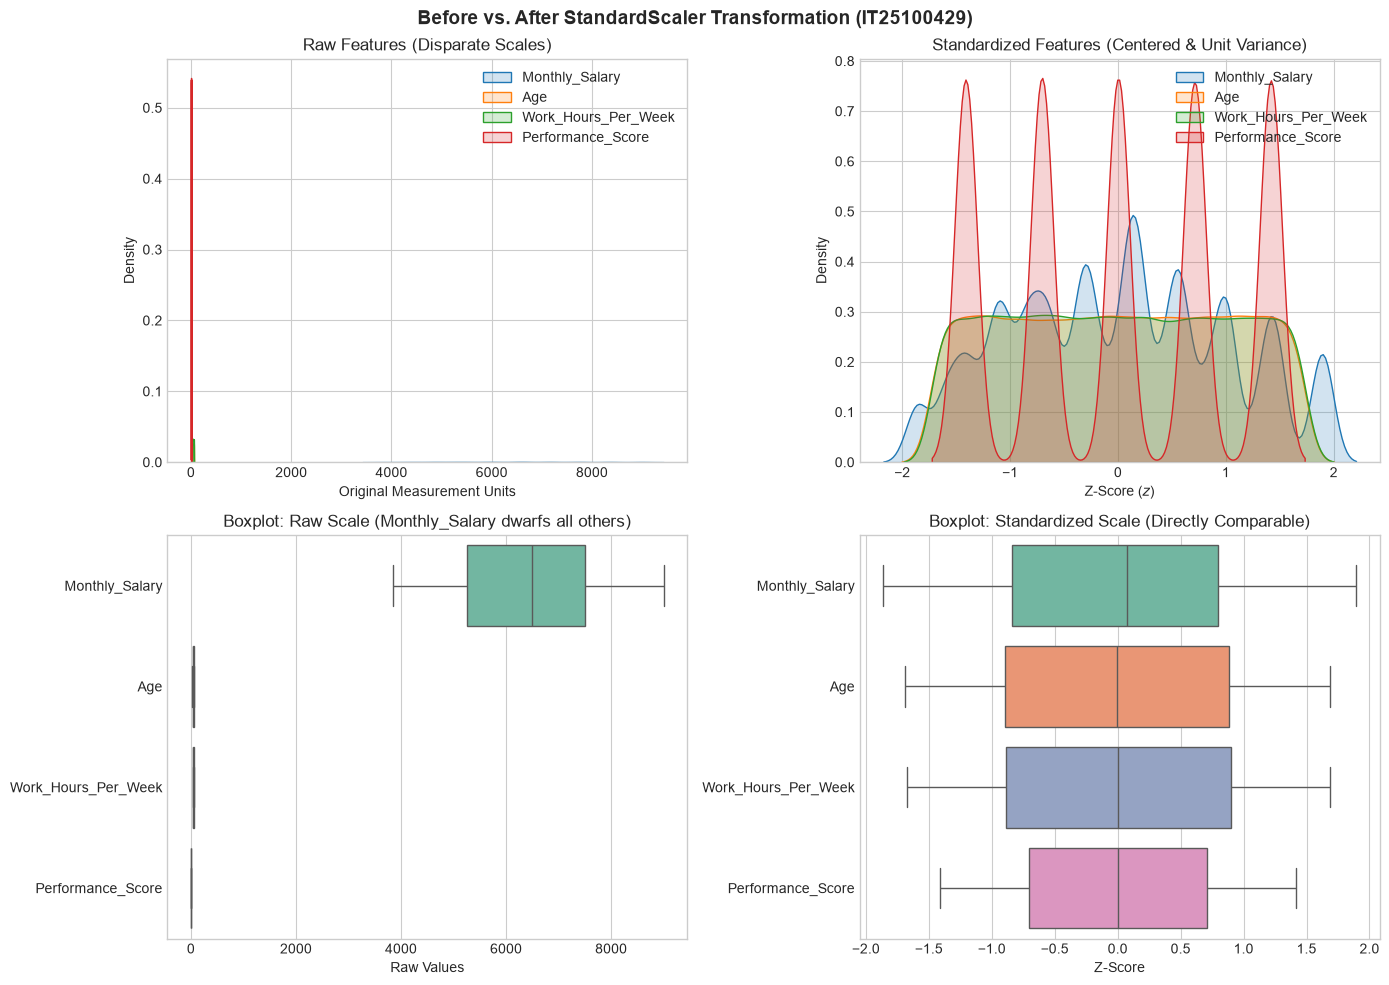

In [7]:
# ============================================================
# Cell 9: Distribution Comparison (Raw vs Standardized)
# ============================================================

sample_features = ["Monthly_Salary", "Age", "Work_Hours_Per_Week", "Performance_Score"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Before vs. After StandardScaler Transformation (IT25100429)", fontsize=14, fontweight="bold", y=0.98)

# Plot 1: Raw distributions on one plot (demonstrating magnitude disparity)
for col in sample_features:
    sns.kdeplot(X_raw[col], ax=axes[0, 0], label=col, fill=True, alpha=0.2)
axes[0, 0].set_title("Raw Features (Disparate Scales)")
axes[0, 0].set_xlabel("Original Measurement Units")
axes[0, 0].legend(loc="upper right")

# Plot 2: Standardized distributions (demonstrating scale alignment)
for col in sample_features:
    sns.kdeplot(X_scaled[col], ax=axes[0, 1], label=col, fill=True, alpha=0.2)
axes[0, 1].set_title("Standardized Features (Centered & Unit Variance)")
axes[0, 1].set_xlabel("Z-Score ($z$)")
axes[0, 1].legend(loc="upper right")

# Plot 3: Boxplot before scaling
sns.boxplot(data=X_raw[sample_features], ax=axes[1, 0], orient="h", palette="Set2")
axes[1, 0].set_title("Boxplot: Raw Scale (Monthly_Salary dwarfs all others)")
axes[1, 0].set_xlabel("Raw Values")

# Plot 4: Boxplot after scaling
sns.boxplot(data=X_scaled[sample_features], ax=axes[1, 1], orient="h", palette="Set2")
axes[1, 1].set_title("Boxplot: Standardized Scale (Directly Comparable)")
axes[1, 1].set_xlabel("Z-Score")

plt.tight_layout()
plt.show()

## 3. Interpretation of Results & Significance for PCA

### Empirical Observations:
1. **Centering at Zero ($\mu \approx 0.0$):** Every standardized feature exhibits a mean on the order of $10^{-16}$, representing computational zero.
2. **Unit Variance ($\sigma = 1.0$):** Every feature now possesses an identical variance of exactly $1.0$, meaning each unit along the axis corresponds strictly to one standard deviation.
3. **Preservation of Distribution Shape:** Z-score standardization is a linear affine transformation ($z = a x + b$). It does **not** distort the underlying shape, skewness, or kurtosis of the original feature; it simply re-centers and rescales the axis.

### Why Scaling is Strictly Mandatory for PCA:
- **Covariance vs. Correlation:** Applying PCA directly to unscaled data performs eigen-decomposition on the sample *covariance matrix* ($\Sigma$). High-variance variables (`Monthly_Salary` with $\sigma \approx 1371.68$) completely dominate the first principal component (PC1) simply because their numerical variance is arbitrarily larger.
- **Fair Variance Representation:** By standardizing all features to $\sigma = 1.0$, PCA decomposes the *correlation matrix* ($R$), ensuring that every predictor has equal opportunity to contribute to explained variance based on statistical relationships rather than arbitrary units of measurement (e.g., dollars vs. years).

## 4. Critical Methodological Nuances

### 1. Standardization (Z-score) vs. Min-Max Normalization
- **Standardization ($Z$-Score):** Rescales to $\mu = 0, \sigma = 1$ without upper/lower boundaries. It preserves outlier distances and does not compress variance if rare extreme observations exist. Ideal for algorithms assuming zero-centered inputs (PCA, logistic regression, RBF kernels).
- **Min-Max Normalization:** Binds features strictly to $[0, 1]$ via $x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$. Highly sensitive to outliers (a single extreme value squashes the remaining distribution into a narrow interval). Ideal for image pixel intensities or neural activations requiring bounded inputs.

### 2. Model Nuance: Not Every Model Needs Scaling
- **Requires Scaling:** 
  - **PCA:** Eigenvectors reflect axis variance; unscaled data skews loadings toward large numbers.
  - **Logistic Regression / Neural Networks:** Scale differences induce ill-conditioned optimization landscapes, distorting regularization penalties ($L_1/L_2$).
  - **Distance-based algorithms ($k$-NN, SVM):** Distances in Euclidean space are dominated by large-scale dimensions.
- **Scale-Invariant (Does NOT Require Scaling):**
  - **Tree-Based Ensembles (CatBoost, XGBoost, LightGBM, EBM, Random Forest):** Decision trees evaluate monotonic threshold splits ($x_j > \theta$). Because order is invariant to monotonic transformations, scaling neither improves nor alters tree splitting decisions.

### 3. Data Leakage Prevention in Real Pipelines
- **The Golden Rule:** Never call `fit_transform()` across the entire dataset before train/validation splitting.
- **Fold-Local Fitting:** Scalers must compute $\mu_{train}$ and $\sigma_{train}$ **strictly on outer training folds**. Test/validation folds and formal holdouts must only receive `.transform()` using the stored training statistics:
  $$z_{val} = \frac{x_{val} - \mu_{train}}{\sigma_{train}}$$
- This strict protocol is automated in our project pipeline using scikit-learn `Pipeline` and `ColumnTransformer` inside `run_5fold_cv()`.

## 5. Summary & Viva Defense Points

### Summary of Completed Preprocessing:
1. Successfully isolated the 13 approved numerical and ordinal features on the 80,000-record development set.
2. Verified that raw features spanned widely disparate ranges (from $[0, 2]$ up to $[3850, 9000]$).
3. Successfully applied `StandardScaler`, yielding verified properties ($\mu = 0.0, \sigma = 1.0$) across all 13 features without distorting distribution shapes.
4. Demonstrated that scaling levels the playing field across predictors, directly supporting the project's **PCA analysis** and **Logistic Regression baseline** (in Notebook `04a_pca_analysis.ipynb`), while respecting that headline tree models (CatBoost, XGBoost, EBM) remain scale-invariant.